In [1]:
import sys, pathlib
sys.path.append(str(pathlib.Path().resolve().parent))
from src.graph_utils import plot_weighted_graph, compute_Q, ktte,kttw
from src.graph_dataset_preparation import load_mutag, add_uniform_weights, ensure_unique_edge_weights

In [2]:
import osmnx as ox
import networkx as nx
import numpy as np
from tqdm import tqdm

N_TOTAL = 400
R_GLOBAL = 1000
R_LOCAL = 150

CITY_CONFIG = {
    "Chicago": (41.87, -87.63),
    "Ufa": (54.73, 55.95),
}

GRAPHS_PER_CITY = N_TOTAL // len(CITY_CONFIG)
NETWORK_TYPE = "drive"

np.random.seed(42)


def has_cycle(G):
    """
    Returns True if graph has at least one cycle.
    Equivalent to genus > 0.
    """
    if not nx.is_connected(G):
        return False
    return not nx.is_forest(G)


def extract_local_graph(G_large, center_node, radius):

    nodes_within_radius = nx.single_source_dijkstra_path_length(
        G_large,
        center_node,
        cutoff=radius,
        weight="length"
    ).keys()

    G_sub = G_large.subgraph(nodes_within_radius).copy()

    # Skip empty
    if G_sub.number_of_edges() == 0:
        return None

    G_sub = ox.convert.to_undirected(G_sub)

    # Remove isolates
    G_sub.remove_nodes_from(list(nx.isolates(G_sub)))

    # Skip empty again
    if G_sub.number_of_edges() == 0:
        return None

    # Keep largest connected component only
    if not nx.is_connected(G_sub):
        largest_cc = max(nx.connected_components(G_sub), key=len)
        G_sub = G_sub.subgraph(largest_cc).copy()

    if not has_cycle(G_sub):
        return None

    return G_sub


def generate_urn2_1s_cycle_only():

    all_graphs = []

    for city_name, (lat, lon) in CITY_CONFIG.items():

        print(f"\nDownloading large graph for {city_name}...")

        G_large = ox.graph_from_point(
            (lat, lon),
            dist=R_GLOBAL,
            network_type=NETWORK_TYPE,
            simplify=True
        )

        G_large = ox.convert.to_undirected(G_large)

        nodes = list(G_large.nodes)

        print(f"Sampling {GRAPHS_PER_CITY} cycle-containing graphs from {city_name}...")

        count = 0
        attempts = 0

        while count < GRAPHS_PER_CITY:

            center_node = np.random.choice(nodes)

            G_local = extract_local_graph(
                G_large,
                center_node,
                R_LOCAL
            )

            attempts += 1

            if G_local is not None:
                all_graphs.append(G_local)
                count += 1

        print(f"Accepted {count} graphs after {attempts} attempts.")

    return all_graphs


# ----------------------------------------------------------
# RUN
# ----------------------------------------------------------

graphs = generate_urn2_1s_cycle_only()

print("\nDataset generated.")
print(f"Total graphs: {len(graphs)}")



Sampling 200 cycle-containing graphs from Chicago...
Accepted 200 graphs after 551 attempts.

Sampling 200 cycle-containing graphs from Ufa...
Accepted 200 graphs after 741 attempts.

Dataset generated.
Total graphs: 400


In [3]:
for i in range(0, len(graphs)):
    graphs[i] = graphs[i].to_undirected()


for G in graphs:
    for u, v, k, data in G.edges(keys=True, data=True):
        data["weight"] = data["length"]


def normalize_edge_weights(G, weight_attr="weight"):
    # Get maximum weight
    max_weight = max(
        data.get(weight_attr, 1)
        for _, _, data in G.edges(data=True)
    )
    
    # Avoid division by zero
    if max_weight == 0:
        return G

    # Normalize weights
    for u, v, data in G.edges(data=True):
        data[weight_attr] = data.get(weight_attr, 1) / max_weight

    return G

graphs = ensure_unique_edge_weights(graphs)

(<Figure size 800x800 with 1 Axes>, <Axes: >)

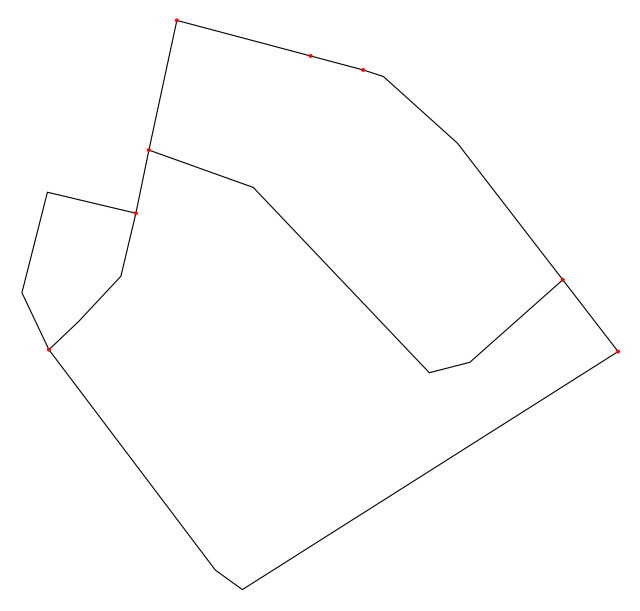

In [4]:
ox.plot_graph(
        graphs[399],
        node_size=8,          # vertices visible
        node_color="red",
        edge_linewidth=0.8,   # edges visible
        edge_color="black",
        bgcolor="white",
        show=False,
        close=False,
    )

In [5]:
import networkx as nx

no_hole_indices = [
    i for i, G in enumerate(graphs)
    if nx.is_forest(G)
]

print("Graphs without holes (acyclic):", no_hole_indices)


Graphs without holes (acyclic): []


In [6]:
import numpy as np
kts = np.zeros((len(graphs), len(graphs)), dtype=float)

for i in range(len(graphs)):
    for j in range(len(graphs)):
        Q1 = compute_Q(graphs[i])
        Q2 = compute_Q(graphs[j])
        kts[i, j] = kttw(Q1, Q2, gamma=1.25) #best one yet is 1.25
        print(f"Kernel between graphs {i} and {j}: {kts[i, j]}")

Kernel between graphs 0 and 0: 1.000000000000142
Kernel between graphs 0 and 1: 8.062657135428595e-19
Kernel between graphs 0 and 2: 1.6918359034564e-156
Kernel between graphs 0 and 3: 7.647305383895069e-184
Kernel between graphs 0 and 4: 0.26919119782290424
Kernel between graphs 0 and 5: 0.4476732875563096
Kernel between graphs 0 and 6: 4.606929725523865e-155
Kernel between graphs 0 and 7: 7.641368312724162e-170
Kernel between graphs 0 and 8: 3.0534524120854504e-305
Kernel between graphs 0 and 9: 5.332855705453826e-184
Kernel between graphs 0 and 10: 2.7494113168698774e-170
Kernel between graphs 0 and 11: 5.089185926285302e-171
Kernel between graphs 0 and 12: 7.647305383895069e-184
Kernel between graphs 0 and 13: 2.0327117346345994e-222
Kernel between graphs 0 and 14: 2.627124787653968e-12
Kernel between graphs 0 and 15: 3.6689850467831432e-155
Kernel between graphs 0 and 16: 5.070177698489072e-205
Kernel between graphs 0 and 17: 1.1826625734895107e-15
Kernel between graphs 0 and 18: 

In [7]:
N_TOTAL = 400
GRAPHS_PER_CITY = N_TOTAL // 2

labels = (
    ["Chicago"] * GRAPHS_PER_CITY +
    ["Ufa"] * GRAPHS_PER_CITY
)


In [8]:
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

clf = SVC(kernel="precomputed")

scores = cross_val_score(clf, kts, labels, cv=10)

print("Mean accuracy:", scores.mean())


Mean accuracy: 0.9349999999999999


In [16]:
import numpy as np

from sklearn.decomposition import KernelPCA
from sklearn.cluster import KMeans
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, accuracy_score
from scipy.optimize import linear_sum_assignment

def mapped_cluster_accuracy_binary(y_true_str, y_pred_cluster, classes=None):
    """
    y_true_str: array of 2-class labels (strings)
    y_pred_cluster: array of cluster ids (0/1)
    Returns: (acc, y_pred_str_mapped, mapping_cluster_to_class_str)
    """
    y_true_str = np.asarray(y_true_str)
    y_pred_cluster = np.asarray(y_pred_cluster)

    if classes is None:
        classes = np.unique(y_true_str)
    classes = np.asarray(classes)
    if len(classes) != 2:
        raise ValueError(f"Expected exactly 2 classes, got {len(classes)}: {classes}")

    # encode true labels to 0/1 in a stable order
    class_to_idx = {c: i for i, c in enumerate(classes)}
    y_true_idx = np.array([class_to_idx[c] for c in y_true_str], dtype=int)

    # Hungarian in index space (0/1)
    C = confusion_matrix(y_true_idx, y_pred_cluster, labels=[0, 1])
    rows, cols = linear_sum_assignment(-C)
    mapping_cluster_to_trueidx = {pred: true for true, pred in zip(rows, cols)}  # {cluster -> true_idx}

    y_pred_idx_mapped = np.array([mapping_cluster_to_trueidx[p] for p in y_pred_cluster], dtype=int)

    # accuracy in index space avoids dtype issues
    acc = accuracy_score(y_true_idx, y_pred_idx_mapped)

    # map back to strings (optional, but nice)
    y_pred_str_mapped = classes[y_pred_idx_mapped]
    mapping_cluster_to_class_str = {cl: classes[ti] for cl, ti in mapping_cluster_to_trueidx.items()}

    return acc, y_pred_str_mapped, mapping_cluster_to_class_str


K = kts
y = np.asarray(labels)

# stable class order for all folds
classes = np.unique(y)

# stratify using numeric codes
_, y_strat = np.unique(y, return_inverse=True)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

accs = []
oof_pred = np.empty_like(y, dtype=object)
fold_mappings = []

for fold, (train_idx, test_idx) in enumerate(cv.split(np.zeros(len(y_strat)), y_strat), start=1):
    K_train = K[np.ix_(train_idx, train_idx)]
    K_test  = K[np.ix_(test_idx, train_idx)]

    kpca = KernelPCA(n_components=10, kernel="precomputed", random_state=42)
    X_train = kpca.fit_transform(K_train)
    X_test  = kpca.transform(K_test)

    kmeans = KMeans(n_clusters=2, random_state=42, n_init=100)
    train_clusters = kmeans.fit_predict(X_train)
    test_clusters  = kmeans.predict(X_test)

    acc, y_test_pred_str, mapping = mapped_cluster_accuracy_binary(
        y_true_str=y[test_idx],
        y_pred_cluster=test_clusters,
        classes=classes
    )

    accs.append(acc)
    oof_pred[test_idx] = y_test_pred_str
    fold_mappings.append(mapping)

print("CV mapped ACC per fold:", accs)
print("Mean CV mapped ACC:", float(np.mean(accs)))
print("Std  CV mapped ACC:", float(np.std(accs)))

# Out-of-fold accuracy directly on strings (now both are strings)
print("OOF mapped ACC:", float(accuracy_score(y, oof_pred)))

CV mapped ACC per fold: [0.5875, 0.55, 0.5875, 0.55, 0.625]
Mean CV mapped ACC: 0.5800000000000001
Std  CV mapped ACC: 0.028062430400804545
OOF mapped ACC: 0.58


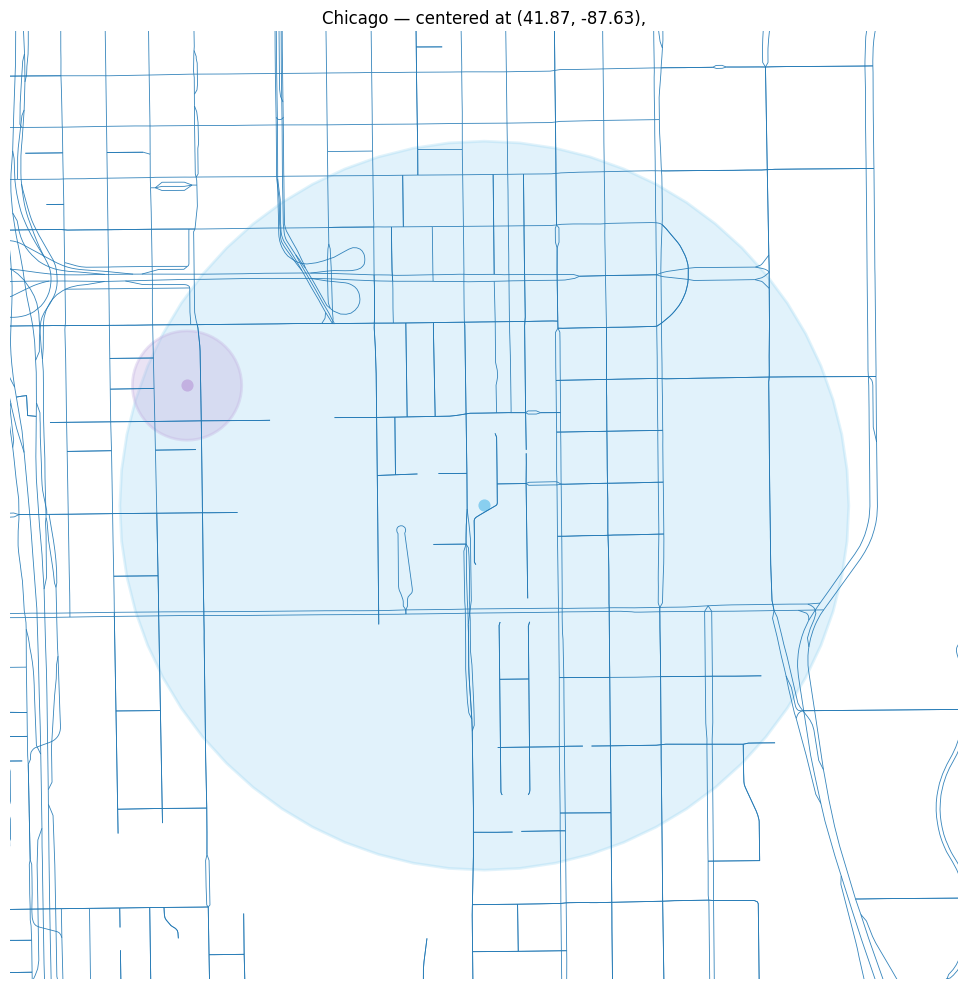

In [12]:
# pip install osmnx geopandas shapely pyproj matplotlib

import random
import numpy as np
import osmnx as ox
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt

# -----------------------------
# Inputs
# -----------------------------
city_name = "Chicago"
center_lat, center_lon = 41.87, -87.63

R_BIG_M = 1000   # 1 km radius
R_SMALL_M = 150  # 150 m radius
network_dist_m = 2500  # how much city to fetch around the center (tweak if you want more/less)

# Colors (you said baby blue + light purple)
BABY_BLUE = "#89CFF0"
LIGHT_PURPLE = "#C3B1E1"

# -----------------------------
# Helpers
# -----------------------------
def random_point_in_circle(center_xy: Point, radius_m: float, rng: np.random.Generator) -> Point:
    # uniform over area: r = sqrt(U)*R, theta = 2*pi*V
    u = rng.random()
    v = rng.random()
    r = radius_m * np.sqrt(u)
    theta = 2 * np.pi * v
    return Point(center_xy.x + r * np.cos(theta), center_xy.y + r * np.sin(theta))

# -----------------------------
# Build graph + project to meters (UTM)
# -----------------------------
ox.settings.use_cache = True
ox.settings.log_console = False

G = ox.graph_from_point((center_lat, center_lon), dist=network_dist_m, network_type="drive", simplify=True)
G_proj = ox.project_graph(G)  # projects to a local metric CRS (usually UTM)

# CRS info
graph_crs = G_proj.graph["crs"]

# Center point as GeoSeries in projected CRS
center_ll = gpd.GeoSeries([Point(center_lon, center_lat)], crs="EPSG:4326")
center_xy = center_ll.to_crs(graph_crs).iloc[0]

# Buffers (in meters because projected CRS)
big_circle = center_xy.buffer(R_BIG_M)

# Random point inside the 1km circle + small buffer
rng = np.random.default_rng(42)  # change seed if you want a different random point
rand_pt = random_point_in_circle(center_xy, R_BIG_M, rng)
small_circle = rand_pt.buffer(R_SMALL_M)

# -----------------------------
# Plot
# -----------------------------
# Convert graph to GeoDataFrames (projected)
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G_proj, nodes=True, edges=True, node_geometry=True, fill_edge_geometry=True)

fig, ax = plt.subplots(figsize=(10, 10))

# Base map: streets
edges_gdf.plot(ax=ax, linewidth=0.6, alpha=0.9)  # (no explicit color; matplotlib default)

# Circles
gpd.GeoSeries([big_circle], crs=graph_crs).plot(
    ax=ax, facecolor=BABY_BLUE, edgecolor=BABY_BLUE, alpha=0.25, linewidth=2
)
gpd.GeoSeries([small_circle], crs=graph_crs).plot(
    ax=ax, facecolor=LIGHT_PURPLE, edgecolor=LIGHT_PURPLE, alpha=0.35, linewidth=2
)

# Points
gpd.GeoSeries([center_xy], crs=graph_crs).plot(ax=ax, color=BABY_BLUE, markersize=60)
gpd.GeoSeries([rand_pt], crs=graph_crs).plot(ax=ax, color=LIGHT_PURPLE, markersize=60)

# Nice view: focus on the big circle bounds (with a little padding)
minx, miny, maxx, maxy = big_circle.bounds
pad = 300  # meters
ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)

ax.set_title(f"{city_name} — centered at ({center_lat}, {center_lon}),", fontsize=12)
ax.set_axis_off()
plt.savefig(f"{city_name}_map.png", dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()